# Lab 09 — Gyroscope Characterisation

**Aim.** Estimate the yaw-gyro bias, bias drift, output resolution, noise, measurement range and scale-factor error from the supplied TRIK log. Then implement a software gyro model and compare its output with the recorded signal.

This notebook follows the lab requirements but uses a reorganised workflow and different plots/calculation helpers.

**Input log format (no header):** `t_us, gz_mdeg_s, encL, encR, phase`

- `t_us`: gyroscope timestamp
- `gz_mdeg_s`: yaw rate returned by `read()[2]`, in millidegrees/second
- `encL`, `encR`: left/right encoder readings (treated as degrees)
- `phase`: 0 warm-up, 1 static, 2 rotation trajectory, 3 final rest, 4 hand-spin test

**Important:** the supplied log uses `read()[2]`, not `readRawData()`. Therefore the documented conversion `mdeg/s → deg/s` is used; a separate raw-unit conversion cannot be experimentally identified from this file.

## 1. Libraries and experiment settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Robot geometry from the supplied reference notebook
WHEEL_RADIUS_M = 0.028
AXLE_LENGTH_M = 0.154
ENCODER_TO_DEG = 1.0

# The static phase is designed to last 180 s.
STATIC_DURATION_S = 180.0
LOG_FILE = "lab9_gyro_data.csv"

# Colab upload fallback; in a local Jupyter session place the CSV beside this notebook.
if not Path(LOG_FILE).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith((".csv", ".txt"))]
        if not candidates:
            raise FileNotFoundError("Please upload the supplied gyro log (.csv or .txt).")
        LOG_FILE = candidates[0]
    except ImportError:
        raise FileNotFoundError(
            f"Cannot find {LOG_FILE}. Put the supplied log in the notebook folder."
        )

print("Reading:", LOG_FILE)

Saving lab9_gyro.csv to lab9_gyro.csv
Reading: lab9_gyro.csv


## 2. Read and prepare the measurements
The timestamp counter is converted to seconds using the known 180-second static interval. This also avoids assuming that the counter is already in microseconds.

In [2]:
raw = pd.read_csv(LOG_FILE, header=None)
if raw.shape[1] < 5:
    raise ValueError(f"Expected 5 columns, found {raw.shape[1]}.")

raw = raw.iloc[:, :5].copy()
raw.columns = ["timestamp", "gz_mdeg_s", "encL", "encR", "phase"]
raw = raw.apply(pd.to_numeric, errors="coerce").dropna()

# If the file contains concatenated runs, retain the final continuous run.
restart_points = np.flatnonzero(np.diff(raw["timestamp"].to_numpy()) < 0)
if len(restart_points):
    raw = raw.iloc[restart_points[-1] + 1:].reset_index(drop=True)

raw["phase"] = raw["phase"].round().astype(int)
static_rows = raw[raw["phase"] == 1]
if len(static_rows) < 10:
    raise ValueError("Phase 1 (static measurement) is missing or too short.")

counter_span = static_rows["timestamp"].iloc[-1] - static_rows["timestamp"].iloc[0]
tick_us = STATIC_DURATION_S * 1e6 / counter_span
# The supplied TRIK timestamp is expected to be a 256-us counter tick.
if abs(tick_us - 256.0) < 5.0:
    tick_us = 256.0

raw["time_s"] = (raw["timestamp"] - raw["timestamp"].iloc[0]) * tick_us / 1e6
raw["gyro_dps"] = raw["gz_mdeg_s"] / 1000.0
raw["encoder_heading_deg"] = (
    WHEEL_RADIUS_M / AXLE_LENGTH_M
    * np.radians((raw["encR"] - raw["encL"]) * ENCODER_TO_DEG)
    * 180.0 / np.pi
)

# Relative time for each phase
raw["phase_time_s"] = raw.groupby("phase")["time_s"].transform(
    lambda x: x - x.iloc[0]
)

phase_summary = raw.groupby("phase").agg(
    samples=("timestamp", "size"),
    first_time_s=("time_s", "min"),
    last_time_s=("time_s", "max"),
    gyro_min_dps=("gyro_dps", "min"),
    gyro_max_dps=("gyro_dps", "max")
)
print(f"Timestamp tick: {tick_us:.1f} us")
print(f"Mean sample interval: {raw.time_s.diff().median()*1000:.1f} ms (median)")
display(phase_summary.round(3))

Timestamp tick: 256.0 us
Mean sample interval: 83.5 ms (median)


,samples,first_time_s,last_time_s,gyro_min_dps,gyro_max_dps
phase,,,,,
0,1339,0.000,119.876,0.201,0.682
1,2023,119.970,299.867,0.122,0.743
2,387,299.951,335.153,-286.440,286.527
3,35,335.236,338.196,-29.618,1.137
4,341,338.280,368.249,-103.880,160.650


## 3. Static offset calibration — bias $b_0$
The baseline estimate is the average of the first 30 seconds of the static phase. The calibration-time curve helps judge whether a shorter or longer interval changes the estimate substantially.

30-s bias estimate: 0.44761 deg/s
Standard error:     0.00406 deg/s


,calibration_time_s,bias_deg_s,standard_error_deg_s
0,1.0,0.47375,0.02073
1,2.0,0.48217,0.01534
2,5.0,0.47357,0.00923
3,10.0,0.45760,0.00698
4,20.0,0.45848,0.00469
5,30.0,0.44761,0.00406


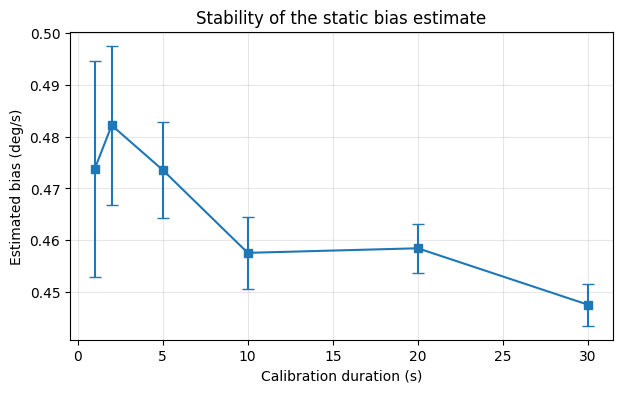

In [3]:
static = raw[raw.phase == 1].copy()
t_static = static.phase_time_s.to_numpy()
w_static = static.gyro_dps.to_numpy()

cal_mask = t_static <= 30.0
b0_30 = float(np.mean(w_static[cal_mask]))
se_30 = float(np.std(w_static[cal_mask], ddof=1) / np.sqrt(cal_mask.sum()))
print(f"30-s bias estimate: {b0_30:.5f} deg/s")
print(f"Standard error:     {se_30:.5f} deg/s")

calibration_times = np.array([1, 2, 5, 10, 20, 30], dtype=float)
bias_curve = []
bias_se = []
for duration in calibration_times:
    selected = w_static[t_static <= duration]
    bias_curve.append(np.mean(selected))
    bias_se.append(np.std(selected, ddof=1) / np.sqrt(len(selected)))

bias_table = pd.DataFrame({
    "calibration_time_s": calibration_times,
    "bias_deg_s": bias_curve,
    "standard_error_deg_s": bias_se
})
display(bias_table.round(5))

plt.figure(figsize=(7, 4))
plt.errorbar(calibration_times, bias_curve, yerr=bias_se, marker="s", capsize=4)
plt.xlabel("Calibration duration (s)")
plt.ylabel("Estimated bias (deg/s)")
plt.title("Stability of the static bias estimate")
plt.grid(alpha=0.3)
plt.show()

### Robust calibration function
This implementation uses the median and median absolute deviation (MAD) to reject isolated outliers, then averages the retained samples. The chosen calibration interval is 10 seconds; change it after inspecting the bias-time curve.

In [4]:
CALIBRATION_SECONDS = 10.0

def calibrate_gyro(static_log, duration_s=CALIBRATION_SECONDS):
    """Estimate gyro bias from a static log with MAD-based outlier rejection."""
    x = static_log.loc[
        static_log["phase_time_s"] <= duration_s, "gyro_dps"
    ].dropna().to_numpy()

    if len(x) == 0:
        raise ValueError("No static samples found in the selected calibration interval.")

    median = np.median(x)
    mad = np.median(np.abs(x - median))
    if mad == 0:
        keep = np.ones(len(x), dtype=bool)
    else:
        robust_sigma = 1.4826 * mad
        keep = np.abs(x - median) <= 3.0 * robust_sigma

    if keep.sum() == 0:
        raise ValueError("Outlier rejection removed every calibration sample.")

    return float(np.mean(x[keep]))

b0 = calibrate_gyro(static)
print(f"Robust bias (T={CALIBRATION_SECONDS:g} s): {b0:.5f} deg/s")

Robust bias (T=10 s): 0.45615 deg/s


## 4. Bias drift — parameter $d$
The static record is divided into 30-second windows. A straight-line fit to the window means estimates the change in bias over time.

Estimated bias drift d: -0.006733 (deg/s)/min


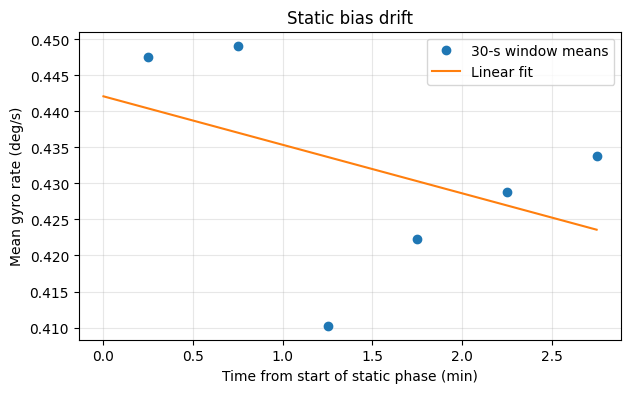

Raw static heading drift slope (approx): 25.6802 deg/min
Expected bias-only drift b0*60:          27.3688 deg/min
Residual heading at 1 min after calibration: -0.4805 deg
Residual heading at 2 min after calibration: -2.8505 deg
Residual heading at 3 min after calibration: -4.3258 deg


In [5]:
window_s = 30.0
window_centres = []
window_means = []

for start in np.arange(0, STATIC_DURATION_S, window_s):
    part = static[
        (static.phase_time_s >= start)
        & (static.phase_time_s < start + window_s)
    ]
    if len(part) >= 3:
        window_centres.append(part.phase_time_s.mean())
        window_means.append(part.gyro_dps.mean())

window_centres = np.asarray(window_centres)
window_means = np.asarray(window_means)

if len(window_means) >= 2:
    drift_slope, drift_intercept = np.polyfit(window_centres / 60.0, window_means, 1)
else:
    drift_slope, drift_intercept = np.nan, np.nan

# d is expressed as change in bias (deg/s) per minute.
d_deg_s_per_min = drift_slope
print(f"Estimated bias drift d: {d_deg_s_per_min:.6f} (deg/s)/min")

plt.figure(figsize=(7, 4))
plt.plot(window_centres / 60, window_means, "o", label="30-s window means")
if np.isfinite(drift_slope):
    xfit = np.linspace(0, max(window_centres / 60), 100)
    plt.plot(xfit, drift_slope*xfit + drift_intercept, label="Linear fit")
plt.xlabel("Time from start of static phase (min)")
plt.ylabel("Mean gyro rate (deg/s)")
plt.title("Static bias drift")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Integrate raw and bias-corrected static rates using actual timestamps.
def integrate_rate(rate, time):
    rate = np.asarray(rate, dtype=float)
    time = np.asarray(time, dtype=float)
    result = np.zeros(len(rate))
    if len(rate) > 1:
        result[1:] = np.cumsum(0.5 * (rate[1:] + rate[:-1]) * np.diff(time))
    return result

theta_static_raw = integrate_rate(w_static, t_static)
theta_static_corrected = integrate_rate(w_static - b0, t_static)

print(f"Raw static heading drift slope (approx): {np.polyfit(t_static/60, theta_static_raw, 1)[0]:.4f} deg/min")
print(f"Expected bias-only drift b0*60:          {b0*60:.4f} deg/min")
for minute in (1, 2, 3):
    idx = np.argmin(np.abs(t_static - minute*60))
    print(f"Residual heading at {minute} min after calibration: "
          f"{theta_static_corrected[idx]:.4f} deg")

## 5. Gyro and wheel-encoder comparison
The trajectory and final-rest phases are used for the heading comparison. Encoder heading is computed from the differential-drive geometry. Rates are estimated numerically from the encoder heading.

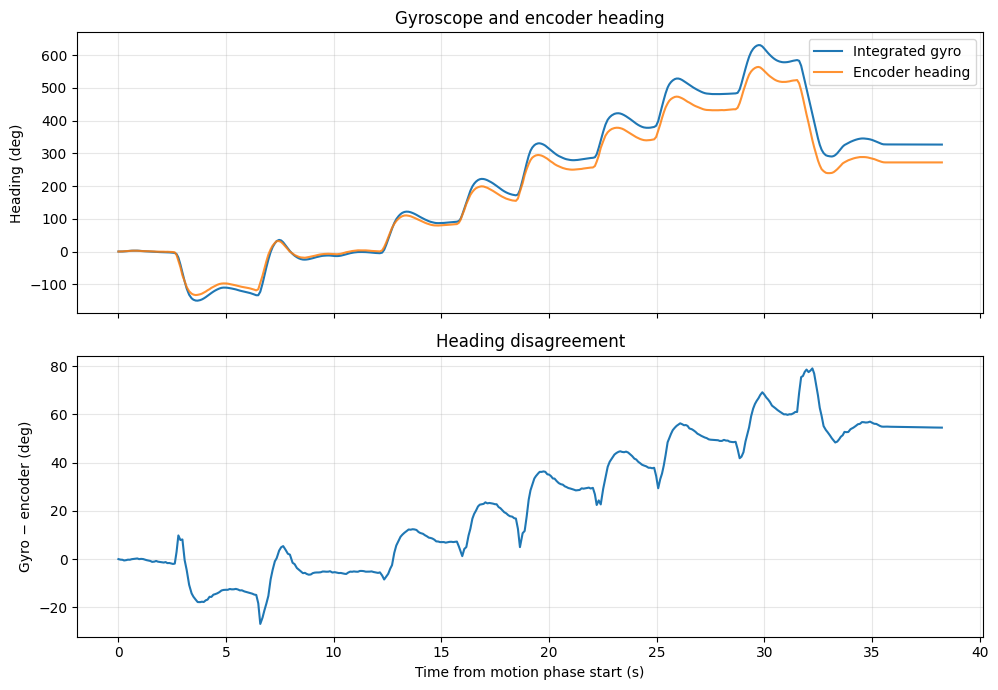

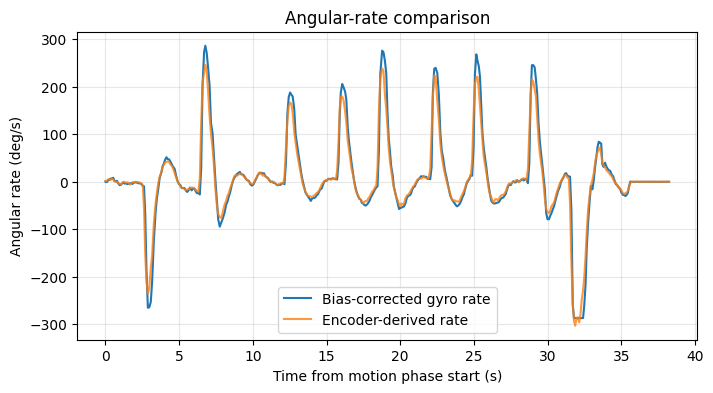

In [6]:
motion = raw[raw.phase.isin([2, 3])].copy()
motion = motion.sort_values("time_s").reset_index(drop=True)

tm = motion.time_s.to_numpy()
wm = motion.gyro_dps.to_numpy()
theta_g = integrate_rate(wm - b0, tm)
theta_e = motion.encoder_heading_deg.to_numpy()
encoder_rate = np.gradient(theta_e, tm)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(tm - tm[0], theta_g, label="Integrated gyro")
axes[0].plot(tm - tm[0], theta_e, label="Encoder heading", alpha=0.85)
axes[0].set_ylabel("Heading (deg)")
axes[0].set_title("Gyroscope and encoder heading")
axes[0].legend()
axes[0].grid(alpha=0.3)

heading_error = theta_g - theta_e
axes[1].plot(tm - tm[0], heading_error)
axes[1].set_xlabel("Time from motion phase start (s)")
axes[1].set_ylabel("Gyro − encoder (deg)")
axes[1].set_title("Heading disagreement")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(tm - tm[0], wm - b0, label="Bias-corrected gyro rate")
plt.plot(tm - tm[0], encoder_rate, label="Encoder-derived rate", alpha=0.8)
plt.xlabel("Time from motion phase start (s)")
plt.ylabel("Angular rate (deg/s)")
plt.title("Angular-rate comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Measurement range — saturation check
The hand-spin phase (4) and commanded rotation phase (2) are inspected together. The largest recorded values are reported as observed extrema; a flat plateau should be visible before claiming a true sensor saturation limit.

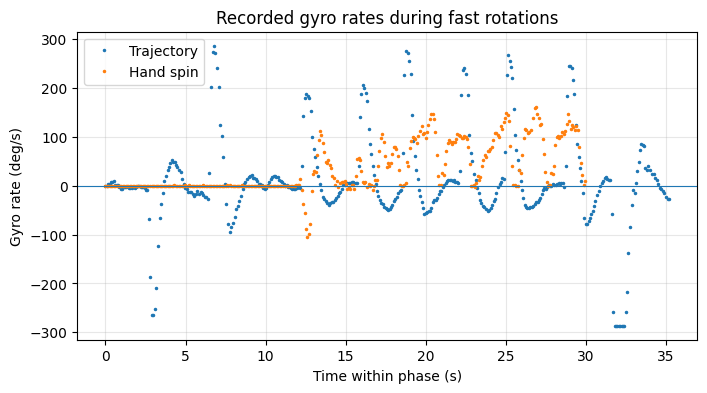

Observed positive peak: 286.527 deg/s
Observed negative peak: -286.440 deg/s
These are observed peaks, not automatically the sensor's saturation limits.


In [7]:
range_data = raw[raw.phase.isin([2, 4])].copy()
if len(range_data):
    plt.figure(figsize=(8, 4))
    for ph, label in [(2, "Trajectory"), (4, "Hand spin")]:
        part = range_data[range_data.phase == ph]
        if len(part):
            plt.plot(part.phase_time_s, part.gyro_dps, ".", ms=3, label=label)
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Time within phase (s)")
    plt.ylabel("Gyro rate (deg/s)")
    plt.title("Recorded gyro rates during fast rotations")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    positive_peak = range_data.gyro_dps.max()
    negative_peak = range_data.gyro_dps.min()
    print(f"Observed positive peak: {positive_peak:.3f} deg/s")
    print(f"Observed negative peak: {negative_peak:.3f} deg/s")
    print("These are observed peaks, not automatically the sensor's saturation limits.")
else:
    positive_peak, negative_peak = np.nan, np.nan
    print("No rotation or hand-spin samples were found.")

## 7. Output resolution — $\Delta$
The smallest non-zero gap between distinct static output levels is used as a practical estimate of the quantisation step.

In [8]:
static_levels = np.sort(static.gz_mdeg_s.dropna().unique())
level_gaps = np.diff(static_levels)
positive_gaps = level_gaps[level_gaps > 0]

if len(positive_gaps):
    delta_mdeg_s = float(np.min(positive_gaps))
    delta_dps = delta_mdeg_s / 1000.0
    print(f"Smallest observed output step: {delta_mdeg_s:g} mdeg/s")
    print(f"Resolution estimate:           {delta_dps:.6f} deg/s")
else:
    delta_dps = np.nan
    print("Not enough distinct static output levels to estimate resolution.")

Smallest observed output step: 8 mdeg/s
Resolution estimate:           0.008000 deg/s


## 8. Noise level — $\sigma$
Noise is calculated from the static samples after subtracting the robust bias. The histogram is compared with a Gaussian having the same mean and standard deviation.

Noise standard deviation sigma: 0.07573 deg/s
Variance R = sigma^2:            0.0057343 (deg/s)^2


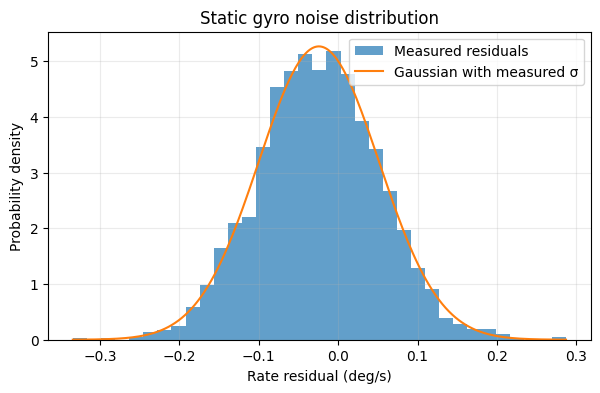

In [9]:
noise = w_static - b0
sigma = float(np.std(noise, ddof=1))
print(f"Noise standard deviation sigma: {sigma:.5f} deg/s")
print(f"Variance R = sigma^2:            {sigma**2:.7f} (deg/s)^2")

plt.figure(figsize=(7, 4))
plt.hist(noise, bins=35, density=True, alpha=0.7, label="Measured residuals")
x = np.linspace(noise.min(), noise.max(), 300)
gaussian = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-noise.mean())/sigma)**2)
plt.plot(x, gaussian, label="Gaussian with measured σ")
plt.xlabel("Rate residual (deg/s)")
plt.ylabel("Probability density")
plt.title("Static gyro noise distribution")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 9. Scale factor and rotation direction — $s$
A linear fit of integrated gyro heading against encoder heading estimates the gain. The slope is $1+s$. CW and CCW subsets are fitted separately where there are enough samples. Encoder rate is used to classify direction.

Overall slope (1+s): 1.12681
Overall scale-factor error: 12.68%
Fit R²: 0.9983
CCW: slope=1.12259, scale error=12.26%, R²=0.9987, samples=187
CW: slope=1.13041, scale error=13.04%, R²=0.9983, samples=196


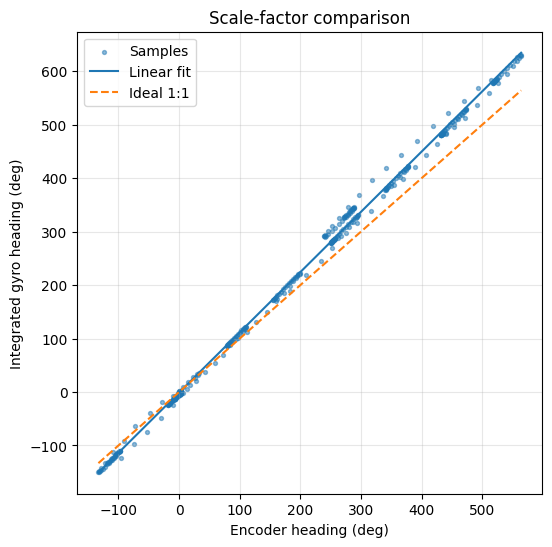

In [10]:
valid = np.isfinite(theta_g) & np.isfinite(theta_e) & np.isfinite(encoder_rate)
valid &= np.abs(encoder_rate) > 0.5

def fit_scale(x_encoder, y_gyro):
    if len(x_encoder) < 5 or np.ptp(x_encoder) == 0:
        return np.nan, np.nan, np.nan
    slope, intercept = np.polyfit(x_encoder, y_gyro, 1)
    prediction = slope*x_encoder + intercept
    ss_res = np.sum((y_gyro - prediction)**2)
    ss_tot = np.sum((y_gyro - np.mean(y_gyro))**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    return slope, intercept, r2

slope_all, intercept_all, r2_all = fit_scale(theta_e[valid], theta_g[valid])
scale_error_all_pct = (slope_all - 1) * 100 if np.isfinite(slope_all) else np.nan
print(f"Overall slope (1+s): {slope_all:.5f}")
print(f"Overall scale-factor error: {scale_error_all_pct:.2f}%")
print(f"Fit R²: {r2_all:.4f}")

for direction, mask in [
    ("CCW", valid & (encoder_rate > 0)),
    ("CW", valid & (encoder_rate < 0))
]:
    slope, intercept, r2 = fit_scale(theta_e[mask], theta_g[mask])
    err_pct = (slope - 1)*100 if np.isfinite(slope) else np.nan
    print(f"{direction}: slope={slope:.5f}, scale error={err_pct:.2f}%, R²={r2:.4f}, samples={mask.sum()}")

if np.isfinite(slope_all):
    fit_x = np.linspace(np.min(theta_e[valid]), np.max(theta_e[valid]), 100)
    plt.figure(figsize=(6, 6))
    plt.scatter(theta_e[valid], theta_g[valid], s=8, alpha=0.5, label="Samples")
    plt.plot(fit_x, slope_all*fit_x + intercept_all, label="Linear fit")
    plt.plot(fit_x, fit_x, "--", label="Ideal 1:1")
    plt.xlabel("Encoder heading (deg)")
    plt.ylabel("Integrated gyro heading (deg)")
    plt.title("Scale-factor comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

## 10. Simulated gyroscope
The model applies scale factor, bias, linear drift, Gaussian noise, saturation and quantisation. The scale factor estimated above is used when it is available; otherwise it is set to zero and clearly marked as a fallback.

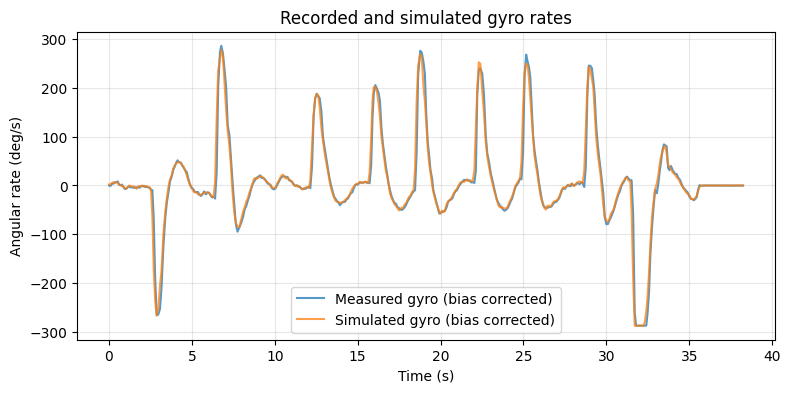

In [11]:
scale_error = (slope_all - 1) if np.isfinite(slope_all) else 0.0
if not np.isfinite(slope_all):
    print("Scale fit unavailable: simulation uses s = 0 as a fallback.")

# The drift estimate is converted from (deg/s)/min to (deg/s)/s.
drift_per_second = d_deg_s_per_min / 60.0 if np.isfinite(d_deg_s_per_min) else 0.0

# A finite saturation estimate is only a provisional bound from observed peaks.
observed_limit = max(abs(positive_peak), abs(negative_peak)) if len(range_data) else np.inf

def gyro_sim(omega_true, time_s, seed=7):
    """Simulate the measured yaw rate using identified parameters."""
    omega_true = np.asarray(omega_true, dtype=float)
    time_s = np.asarray(time_s, dtype=float)
    rng = np.random.default_rng(seed)

    ideal_with_errors = (
        (1 + scale_error) * omega_true
        + b0
        + drift_per_second * time_s
        + rng.normal(0.0, sigma, size=omega_true.shape)
    )
    clipped = np.clip(ideal_with_errors, -observed_limit, observed_limit)

    if np.isfinite(delta_dps) and delta_dps > 0:
        clipped = np.round(clipped / delta_dps) * delta_dps
    return clipped

# Use the encoder-derived rate as the best available reference input.
simulated_rate = gyro_sim(encoder_rate, tm - tm[0])

plt.figure(figsize=(9, 4))
plt.plot(tm - tm[0], wm - b0, label="Measured gyro (bias corrected)", alpha=0.75)
plt.plot(tm - tm[0], simulated_rate - b0, label="Simulated gyro (bias corrected)", alpha=0.75)
plt.xlabel("Time (s)")
plt.ylabel("Angular rate (deg/s)")
plt.title("Recorded and simulated gyro rates")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Identified parameter summary

In [12]:
parameter_rows = [
    ["Offset / bias", "b0", b0, "deg/s", f"Robust mean of first {CALIBRATION_SECONDS:g} s of static phase"],
    ["Bias drift", "d", d_deg_s_per_min, "(deg/s)/min", "Linear fit to 30-s static window means"],
    ["Uncorrected heading drift", "", b0*60, "deg/min", "Bias estimate multiplied by 60"],
    ["Observed positive peak", "+ω observed", positive_peak, "deg/s", "Maximum recorded rate in phases 2 and 4"],
    ["Observed negative peak", "−ω observed", negative_peak, "deg/s", "Minimum recorded rate in phases 2 and 4"],
    ["Resolution", "Δ", delta_dps, "deg/s", "Smallest positive gap between distinct static levels"],
    ["Noise standard deviation", "σ", sigma, "deg/s", "Standard deviation of static residuals"],
    ["Scale-factor error", "s", scale_error_all_pct, "%", "Slope of gyro heading vs encoder heading, minus 1"],
]
parameter_table = pd.DataFrame(
    parameter_rows, columns=["Parameter", "Symbol", "Estimate", "Unit", "Method"]
)
display(parameter_table.round(5))

,Parameter,Symbol,Estimate,Unit,Method
0,Offset / bias,b0,0.45615,deg/s,Robust mean of first 10 s of static phase
1,Bias drift,d,-0.00673,(deg/s)/min,Linear fit to 30-s static window means
2,Uncorrected heading drift,,27.36881,deg/min,Bias estimate multiplied by 60
3,Observed positive peak,+ω observed,286.52700,deg/s,Maximum recorded rate in phases 2 and 4
4,Observed negative peak,−ω observed,-286.44000,deg/s,Minimum recorded rate in phases 2 and 4
5,Resolution,Δ,0.00800,deg/s,Smallest positive gap between distinct static ...
6,Noise standard deviation,σ,0.07573,deg/s,Standard deviation of static residuals
7,Scale-factor error,s,12.68129,%,"Slope of gyro heading vs encoder heading, minus 1"


## 12. Interpretation and limitations

Use the plots and printed estimates above to write the final discussion:

1. **Bias:** report the 30-second mean and explain whether the calibration-time curve becomes stable.
2. **Drift:** compare the fitted drift with the residual integrated heading after bias removal.
3. **Range:** call the observed peaks a saturation limit only if the rate plot shows a clear flat plateau.
4. **Resolution and noise:** distinguish the smallest output increment from the random variation around the bias.
5. **Scale factor:** discuss the fitted slope, CW/CCW differences and the quality of the encoder reference.
6. **Model:** state that the simulation uses `read()[2]` in mdeg/s converted to deg/s, and that the range estimate is provisional unless clipping is visibly confirmed.

**Data limitation:** the supplied file does not contain the floor-mark/protractor slip measurement. Add that independently if it was measured. Encoder readings are treated as degrees, consistent with the supplied reference notebook; verify this against the robot configuration.